# Monte Carlo Risk Assessment for Portfolio Management

## Table of Contents

1. Setting up the environment
2. Project configuration
3. Download and prepare the stock data
4. Build the Monte Carlo return simulations
5. Calculate VaR and CVaR
6. Test VaR forecasts against actual returns
7. Run the workflow end-to-end
8. Conclusions

## Project Objective

The main objective of the project is to understand how statistical models with varying stock-return distributions estimate portfolio risk.

The distributions are assessed using Monte Carlo simulations and evaluated through the Value at Risk (VaR) and Conditional Value at Risk (CVaR) metrics of the simulations.

The three distributions of portfolio returns are Multivariate Normal, Multivariate Student-t, and Historical Simulation of stock returns. To evaluate the validity of each distribution and how accurately they estimate portfolio risk, we perform backtests of the process and compare their VaR metrics to the next day's portfolio returns.

## 1. Setting Up the Environment

In [16]:
import datetime as dt
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

### Importing Libraries
- `datetime (dt)`: For handling date and time operations
- `numpy (np)`: For numerical arrays and linear algebra used in simulations and risk calculations
- `pandas (pd)`: For organizing stock data, returns, and tables in DataFrames and Series
- `yfinance (yf)`: For downloading historical stock-price data from Yahoo Finance
- `matplotlib.pyplot (plt)`: For building plots

## 2. Project Configuration

The companies being analyzed are defined in the `stocks` variable by their stock tickers. To select stocks, 4 industry sectors are randomly chosen, and a company with a market capitalization of at least $100 billion (for start and end dates of the project's timeframe) in each of those sectors is selected. 

The selection process is intended to provide exposure to different industries and reduce concentration in a single sector. The randomization process prevents deliberately choosing industries based on expected performance or personal preferences. The minimum market capitalization requirement ensures that selected companies are large and established, excluding smaller companies whose potentially greater volatility in daily returns may disproportionately influence the portfolio risk analysis.

| Sector | Company | Ticker |
| --- | --- | --- |
| Information Technology | Cisco Systems | CSCO |
| Communication Services | Comcast | CMCSA |
| Health Care | Pfizer | PFE |
| Real Estate | American Tower | AMT |

The amount of money allocated towards each stock at the start of the simulations is defined by the `weights` variable. All weights are equal between stocks (25%) to provide a straightforward portfolio structure without requiring additional assumptions about favorability of each stock. Maintaining equal weights also ensures that risk estimates are compared consistently.

The portfolio's starting value will have a starting value of $1000 (`initial_portfolio = 1000`), meaning an initial investment of $250 per stock.

In [17]:
stocks = ['CSCO', 'CMCSA', 'PFE', 'AMT']
weights = [0.25, 0.25, 0.25, 0.25]
initial_portfolio = 1000

## 3. Download and Prepare the Stock Data

#### Defining the Analysis Date Window

To determine the exact timeframe of stock price data being analyzed, an appropriate sample size is required.

The end date (`end_date`) was hardcoded to September 30, 2026, acting as the fixed cutoff date.

A total of 250 trading days will be analyzed in the simulation. A window of 365 total days (`days_back=365`) factors in non-trading days (weekends, holidays) while retrieving enough trading days for the required 250 trading-day estimation period.

Using this information, we can determine the window's start date (`start_date`).

In [ ]:
def build_window_dates(days_back=365):
    end_date = dt.datetime(2026, 9, 30) #9/30/2026
    start_date = end_date - dt.timedelta(days=days_back)
    return start_date, end_date

start_date, end_date = build_window_dates(days_back=365)

#### Defining the Stock-Data Function

Now that the start and end dates of the 365-day window are determined, we must get the required stock data for simulations.

Using stock data from Yahoo Finance for each stock in the `stocks` variable, we pull the adjusted closing (end of trading day) price for each stock across the final 250 trading days (`trade_days=250`) of the window. These 250 trading days will act as an estimation period. 250 observations is enough to estimate the relationships between the four stocks.

NOTE: Adjusted prices consider corporate actions including stock splits, dividends, and rights offerings.

For each stock, we calculate percentage change in price between each trading day (`returns`), and use it to determine the average percentage daily return for each stock (`mean_returns`). 

We also generate a covarance matrix (`cov_matrix`), measuring the variance of individual stock returns and the relationships between each stock in the portfolio.

In [19]:
def get_data(stocks, start, end, trade_days=250):
    stock_data = yf.download(stocks, start=start, end=end, auto_adjust=True) #download stock data from Yahoo Finance

    if isinstance(stock_data.columns, pd.MultiIndex): #if stock data has multiple columns
        stock_data = stock_data['Close'] #select column labeled 'Close'
    else: #if stock data has 1 column
        if 'Close' in stock_data.columns: #if the 1 column is labeled 'Close'
            stock_data = stock_data[['Close']] #select the column labeled 'Close'
        else: #if the 1 column is not labeled 'Close'
            raise ValueError("The downloaded data does not contain a 'Close' column.") #raise an error
    stock_data = stock_data.reindex(columns=stocks)  # reorder columns to match stocks list
    #stock data is now only closing values for each day in 250-day span

    returns = stock_data.pct_change().tail(trade_days) #compute percentage change in closing value for each day in 250-day span
    mean_returns = returns.mean() #mean of daily returns for the stock
    cov_matrix = returns.cov() #covariance matrix of daily returns for the stock
    return mean_returns, cov_matrix

In [20]:
start_date, end_date = build_window_dates(days_back=365)
mean_returns, cov_matrix = get_data(stocks, start_date, end_date)

print("Mean daily returns (decimal daily return):")
print(mean_returns)
print("\nMean daily returns (%):")
print(mean_returns * 100)
print("\nCovariance matrix (decimal-return units squared):")
print(cov_matrix)

[*********************100%***********************]  4 of 4 completed

Mean daily returns (decimal daily return):
Ticker
CSCO     0.002107
CMCSA   -0.000841
PFE      0.000847
AMT     -0.000303
dtype: float64

Mean daily returns (%):
Ticker
CSCO     0.210716
CMCSA   -0.084088
PFE      0.084746
AMT     -0.030316
dtype: float64

Covariance matrix (decimal-return units squared):
Ticker      CSCO     CMCSA       PFE       AMT
Ticker                                        
CSCO    0.000474 -0.000011 -0.000010 -0.000069
CMCSA  -0.000011  0.000413  0.000050  0.000070
PFE    -0.000010  0.000050  0.000196  0.000058
AMT    -0.000069  0.000070  0.000058  0.000274


## 4. Build the Monte Carlo Return Simulations

In preperation for the Monte Carlo simulations, we must create a mean matrix where each column contains each stock's mean daily return (`mean_returns`), repeated across each column. The number of columns must represent the simulation horizon, also known as the number of trading days being evaluated in each simulation (`num_days`).

This value is set to 250 trading days (approximately 1 year) to generate annual portfolio projections and evaluate longer term portfolio decisions. Since the portfolio is designed for long-term investments, a larger simulation horizon is more applicable than a smaller horizon for high-frequency trading.

In [ ]:
num_days = 250

def build_mean_matrix(mean_returns, num_days):
    mean_values = np.asarray(mean_returns) #converting mean_returns to a column vector of shape (n_stocks, 1)
    mean_returns_matrix = np.tile(mean_values.reshape(-1, 1), (1, num_days)) #repeating mean_values column vector num_days times so each column is identical
    return mean_returns_matrix

In [22]:
mean_m = build_mean_matrix(mean_returns, num_days)

### Run Monte Carlo Simulation Using a Multivariate Normal Distribution

When performing a simulation for a Multivariate Normal Distribution, we must generate an array of randomly distributed normal variables for each day of the simulation, represented by $Z_t$ where $t=day$. The random variables follow a standard multivariate normal distribution, meaning all random variables in the array are standard normal.

$$
Z_t \sim \mathcal{N}(0,I)
$$

These variables are using a random number generator (`rng`), allowing us to control the random sampling process. In addition, specifying `rng` to a specific value reproduces the same results across multiple runs.

Using the covariance matrix of the stocks in the portfolio, we must perform a Cholesky decomposition of the covariance matrix to determine its Cholesky matrix. When the Cholesky matrix ($\Sigma$) is multiplied by its transposed matrix ($L^T$), the result is the covarance matrix ($\Sigma$). 

$$
\Sigma = LL^T
$$


By multiplying the Cholesky matrix ($L$) by the standard normal variables array for a given day ($Z_t$), we can simulate daily returns for stocks that factor in relations between the stocks thenselves. When these variations are added to the average daily returns of each stock ($\mu$), we can estimate the daily returns for each stock for a given day ($R_t$).

$$
R_t = \mu + LZ_t
$$


For each day of the sample ($t$), multiply each stock's simulated daily returns ($R_{i,t}$) by its weight in the portfolio ($w_i$), then add all of these values across each stock ($s$) in the portfolio to get the full portfolio's return for the day ($R_{portfolio,t}$)

$$
R_{portfolio,t}=w_1R_{1,t}+w_2R_{2,t}+...+w_sR_{s,t}
$$


For the first day's ($t=1$) portfolio return ($R_{portfolio,1}$), multiply its compounding factor ($1+R_{portfolio,1}$) by the starting portfolio value ($V_0$) to get the portfolio value for day 1 ($V_{1}$). Each day's new compounding factor ($1+R_{portfolio,t}$) is multiplied by the previous day's portfolio value until the 250th and final day of the simulation ($T$). The value of the portfolio is represented by $V_{1}$. $V_{T}$ represents 250 days of compounded portfolio returns.

$$
V_{T}=V_0(1+R_{portfolio,1})(1+R_{portfolio,2})...(1+R_{portfolio,T})
$$



Repeat all of these processes once for each simulation (`mc_sims=10000`) to generate 10,000 simulated portfolio returns. 10,000 simulations provide a reasonable balance between computational efficiency and accuracy of metrics. All of these simulated daily returns are included in the `portfolio_sims` variable.

In [23]:
mc_sims = 10000

rng = np.random.default_rng(10)

def simulate_normal_model(mean_m, cov_matrix, weights, initial_portfolio, num_days, mc_sims, rng=None):
    if rng is None: #if no random number generator is provided
        rng = np.random.default_rng(10) #create default random number generator

    portfolio_sims = np.full(shape=(num_days, mc_sims), fill_value=0.0) #creates all 0.0 matrix, rows = num_days, columns = mc_sims

    l = np.linalg.cholesky(cov_matrix) #Cholesky decomposition of the covariance matrix comparing stocks to each other

    for m in range(mc_sims): #for each column/simulation
        z = rng.standard_normal(size=(num_days, len(weights))) #array of standard normal vars dimensions (num_days, n_stocks)
        daily_returns = mean_m + l @ z.T #cholesky matrix*standard normal array + mean returns matrix = daily returns for each stock for each day
        portfolio_sims[:, m] = np.cumprod(daily_returns.T @ weights + 1) * initial_portfolio #for each day, multiply each stock's return by its weight to get the days full portfolio return, repeat for each day

    return portfolio_sims

In [24]:
normal_sims = simulate_normal_model(
    mean_m,
    cov_matrix,
    weights,
    initial_portfolio,
    num_days,
    mc_sims,
    rng=rng,
)

### Run Monte Carlo Simulation Using a Multivariate Student-t Distribution

The simulation process for a Multivariate Student-t Distribution is similar to the Normal Distribution simulation, with some modifications. These changes will account for the heavier tails of the Student-t distribution, which can increases the chances of extreme stock returns in either direction.

The process of generating an array of randomly distributed standard normal variables ($Z_t$) remains unchanged. However, we must also generate an array of randomly distributed chi-square variables ($u_t$) for a given day ($t$) to transform the standard normal variables into Student-t distributed random variables.

The chi-square variables for each day ($u_t$) will follow a chi-square distribution ($\chi^2_{df}$), where the degrees of freedom ($df$) determine the shape of the Student-t distribution and heaviness of its tails. Lower degrees of freedom result in heavier tails, making the distribution more likely to generate extreme returns. Lower values produce heavier tails, while higher values produce distributions closer to the Normal distribution. The degrees of freedom is set to 5 (`df=5`) to account for the heavier tails commonly associated with financial return distributions.

$$
u_t \sim \chi^2_{df}
$$



A value of 5 was selected as a modeling assumption to allow for greater tail risk than the Normal distribution while maintaining a reasonable balance between the frequency and magnitude of extreme returns. This provides an alternative to the Normal model for evaluating how heavier-tailed return distributions affect portfolio risk estimates.

The chi-square variables are using the same `rng` random number generator as the normal distribution model.

The Cholesky decomposition process is slightly modified for the Student-t distribution. Since the Student-t distribution has heavier tails and a different variance structure than the standard normal distribution, the covariance matrix ($\Sigma$) must be multiplied by $((df-2)/df)$ before performing the Cholesky decomposition. The resulting lower triangular Cholesky matrix ($L$) and its transpose ($L^T$) produce the scaled covariance matrix. As a result, the Student-t distributed stock returns maintain the same covariance as the Normal Distribution model.

$$
\Sigma \left(\frac{df-2}{df}\right) = LL^T
$$


Next, the standard normal random variables ($Z_t$) are transformed into Student-t distributed random variables ($X_t$) using the formula below.

$$
X_t = \frac{Z_t}{\sqrt{u_t/df}}
$$


Using the modified Cholesky matrix ($L$) and transformed random variables ($X_t$), we can generate simulated daily stock returns by adding the historical average daily returns ($\mu$).

$$
R_t = \mu + LX_t
$$

From this point forward, the process is the same as the Normal Distribution simulation. We multiply each stock's simulated daily returns by its corresponding portfolio weight and sum the weighted returns to calculate the portfolio's daily return. We then compound the daily portfolio returns to calculate the cumulative portfolio value.

The process is repeated for each trading day in the sample to complete 1 simulation. Once 10000 Monte Carlo simulation (`mc_sims`) are generated. The resulting simulated portfolio values are stored in the `portfolio_sims_t` variable.

In [25]:
def simulate_student_t_model(mean_m, cov_matrix, weights, initial_portfolio, num_days, mc_sims, df=5, rng=None):
    if rng is None: #if no random number generator is provided
        rng = np.random.default_rng(10) #create default random number generator

    portfolio_sims_t = np.full(shape=(num_days, mc_sims), fill_value=0.0)

    l = np.linalg.cholesky(cov_matrix * (df - 2) / df) #cholesky decomposition scaled by (df-2)/df to account for the Student-t distribution's heavier tails

    for m in range(mc_sims):
        z = rng.standard_normal(size=(num_days, len(weights)))
        u = rng.chisquare(df, size=num_days).reshape(num_days, 1) #generate chi-square random variables
        x = z / np.sqrt(u / df) #z-term adjusted so the covariance is the same as the multivariate normal distribution
        daily_returns = mean_m + l @ x.T
        portfolio_sims_t[:, m] = np.cumprod(daily_returns.T @ weights + 1) * initial_portfolio

    return portfolio_sims_t

In [26]:
t_sims = simulate_student_t_model(
    mean_m,
    cov_matrix,
    weights,
    initial_portfolio,
    num_days,
    mc_sims,
    df=5,
    rng=rng,
)

#### Downloading Historical Portfolio Returns

The final simulations will utilize the daily stock returns from 250 randomly selected trading days in the past 5 years (`years_back=5`) before the September 30th 2026 end date (the random sampling is done with replacement). 5 years provides a substantial sample size while factoring in how older stock return data may affect future market behavior.

For each trading day in the 5-year sample size, the return of each stock in the portfolio is calculated and pulled into the `portfolio_returns` variable.

In [27]:
def get_historical_portfolio_returns(stocks, weights, years_back=5):
    end_date = pd.Timestamp("2026-09-30").normalize() #fixed end date: 9/30/2026
    start_date = end_date - pd.DateOffset(years=years_back) #date 5 years before the fixed end date

    prices = yf.download(stocks,start=start_date,end=end_date,auto_adjust=True,)['Close'] #closing prices for each stock on each day in 5-year span
    prices = prices.reindex(columns=stocks)  # reorder columns to match stocks list

    returns = prices.pct_change().dropna() #percentage change in closing value for each stock and for each day in 5-year span
    portfolio_returns = returns @ weights #multiplies the returns of each stock by its weight, sums returns for each day to get total portfolio return for each day in 5-year span
    return returns, portfolio_returns

In [28]:
historical_stock_returns, portfolio_returns_past_data = get_historical_portfolio_returns(
    stocks,
    weights,
    years_back=5,
)

[*********************100%***********************]  4 of 4 completed


### Sample Historical Return Days with Replacement to Build a Distribution

In one simulation, 250 trading days from the 5-year window are randomly selected .

For each day of the sample, use each stock's weight in the portfolio to get the full portfolio's return for the day. This is the same method as the other models, except with historical stock returns instead of simulated stock returns. The process is repeated for all 250 days and generates a simulated portfolio value for the simulation.

Repeat this process 10,000 times (same size and reasoning as previous simulations) to generate a daily portfolio return for each simulation (`mc_sims`). All of these simulated portfolio returns are compiled into the `portfolio_hist` variable.

In [29]:
def simulate_random_day_model(historical_stock_returns, weights, initial_portfolio, num_days, mc_sims, rng=None):
    if rng is None: #if no random number generator is provided
        rng = np.random.default_rng(10) #create default random number generator

    portfolio_hist = np.full(shape=(num_days, mc_sims), fill_value=0.0)

    for m in range(mc_sims):
        sample_indices = rng.integers(0, len(historical_stock_returns), size=num_days) #selects random row positions
        sampled_returns = historical_stock_returns.iloc[sample_indices] #selects the data from random row positions to make new dataframe
        portfolio_hist[:, m] = np.cumprod(sampled_returns @ weights + 1) * initial_portfolio #randomly selected returns for each stock put together to completely simulate stock returns for each day

    return portfolio_hist

In [30]:
hist_sims = simulate_random_day_model(
    historical_stock_returns,
    weights,
    initial_portfolio,
    num_days,
    mc_sims,
    rng=rng,
)

## 5. Calculate VaR and CVaR

### Value at Risk: Return the Percentile for a Given Confidence Level

The Value at Risk (VaR) is a way to evaluate lower portfolio return scenarios that are not likely to occur but are still possible. To generate VaR, all simulated returns are gathered to determine the expected amount of money lost for a given percentile (represented by alpha).

Evaluating the bottom 5% of possible portfolio returns (`alpha=5`) means there is a 5% chance the portfolio will lose at least the VaR in value when alpha = 5%. 

In [ ]:
alpha = 5 #5% alpha

def mcValueRisk(returns, alpha=5):
    if isinstance(returns, pd.Series): 
        return np.percentile(returns, alpha) #return the alpha percentile of the returns
    raise TypeError("Expected pandas data series") #raise an error if the input is not a pandas series

### Compute CVaR / Expected Shortfall Below the VaR Threshold

Once Value at Risk (VaR) is generated, it can be used to determine Conditional Value at Risk (CVaR). To determine this, take every simulated portfolio loss greater than the VaR, and determine the mean of these losses. This value represents the average portfolio loss if the return is anywhere below the 5th percentile of simulations.

In [32]:
def mcConditionalValueRisk(returns, alpha=5):
    if isinstance(returns, pd.Series):
        below_var = returns <= mcValueRisk(returns, alpha=alpha) #generate all returns below alpha percentile of returns
        return returns[below_var].mean() #return mean of all returns below alpha percentile of returns
    raise TypeError("Expected pandas data series")

### Summarize VaR and CVaR for Each Model Column

Using all simulated portfolio returns for all three distribution types (`results_df`), VaR and CVaR are generated and compared across each distribution type. The results represent dollar losses relative to the initial $1,000 portfolio value.

In [33]:
def summarize_risk(results_df, initial_portfolio, alpha=5):
    VaR = results_df.apply(lambda col: initial_portfolio - mcValueRisk(col, alpha=alpha)) #for each distribution type, determine VaR by subtracting alpha percentile final return from initial portfolio value
    CondVaR = results_df.apply(lambda col: initial_portfolio - mcConditionalValueRisk(col, alpha=alpha)) #for each distribution type, determine CVaR by subtracting mean of returns below alpha percentile from initial portfolio value
    return pd.DataFrame({'VaR': VaR, 'CVaR': CondVaR})

In [34]:
results_df = pd.DataFrame({
    'normal': normal_sims[-1, :],
    't': t_sims[-1, :],
    'hist': hist_sims[-1, :],
})

risk_summary = summarize_risk(results_df, initial_portfolio, alpha=alpha)
print("Risk Summary")
print(risk_summary)

Risk Summary
               VaR        CVaR
normal  140.202295  188.079098
t       143.344038  194.917414
hist    241.297336  293.079171


## 6. Test VaR Forecasting

### Backtest VaR Models Against Realized Portfolio Returns

The backtest uses a rolling 250 trading-day estimation window to forecast the portfolio's Value at Risk (VaR) for the immediately following trading day(`window_backtest=250`).

For each forecast, the preceding 250 trading days are used to estimate the parameters of the Normal and Student-t distributions and calculate the corresponding VaR thresholds. The Historical model uses the same 250-day window of actual portfolio returns to calculate its historical VaR threshold.

The resulting VaR thresholds are compared against the actual portfolio return observed on the following trading day. This process evaluates how accurately each model forecasts one-day portfolio risk, rather than risk over the entire 250-day estimation period.


| Estimation Window | Evaluation Day | 
| --- | --- | 
| Days 1-250 | Day 251| 
| Days 2-251| Day 252 | 
| Days 3-252| Day 253 |  
| ...| ...|  

For example, the first backtest uses returns from Days 1-250 to calculate a VaR threshold for day 251. Then day 251's actual return is compared to the VaR threshold for Days 1-250. The estimation window advances to days 2-251 to forecast day 252.

### Calculating VaR for Each Backtest Day

#### Normal and Student-t models:

or each rolling 250-day estimation window, the average daily return for each stock (`mu`) and its covariance matrix (`cov`) are calculated. 

Using these parameters, each model is simulated 10,000 times (`num_sims_backtest=10000`). The 5th percentile of the simulated portfolio returns (`alpha_backtest=5`) is used as that day's VaR threshold.

#### Historical model:

The Historical model does not require additional Monte Carlo simulations because its VaR threshold is calculated directly from the 250 observed historical portfolio returns in each estimation window.

The portfolio's actual daily returns over the same 250-day estimation window are calculated using the portfolio weights. The 5th percentile of these historical portfolio returns is used as the model's VaR threshold for the following trading day.

This process is repeated for each subsequent one-day forecast, using the updated 250-day estimation windows to calculate each new VaR value.

#### Evaluating VaR Forecasts:

Violation rate measures the percentage of days where the actual portfolio return falls below its corresponding VaR threshold. Since VaR is calculated using an alpha value of 5%, approximately 5% of actual daily returns are expected to fall below their corresponding VaR values.

A violation rate greater than 5% indicates that the model may be underestimating the portfolio's downside risk, while a rate below 5% may suggest a conservative VaR estimate.

The violation rate is calculated for all three models by comparing each day's portfolio return against their VaR thresholds.

In [35]:
def run_var_backtest(stock_returns, portfolio_returns, weights, window_backtest=250, alpha_backtest=5, num_sims_backtest=10000, df_backtest=5, rng=None):
    if rng is None:  # if no rng is provided
        rng = np.random.default_rng(10)  # create new rng

    backtest_data = pd.DataFrame(
        index=stock_returns.index[window_backtest:],  # index by date, only uses dates after the initial window_backtest period
        columns=['Normal', 'Student-t', 'Historical'],
        dtype=float,
    )
    backtest_data['Actual Return'] = portfolio_returns.iloc[window_backtest:].to_numpy()  # adds actual portfolio returns for each day in the backtest period

    stocks = stock_returns.columns  # stocks are the same as the column names in the stock-returns DataFrame

    for i in range(window_backtest, len(stock_returns)):  # for each day in the backtest period

        #general info
        historical_window = stock_returns.iloc[i - window_backtest:i]  # historical window of stock returns is 250 days before the current day being evaluated
        mu = historical_window.mean().to_numpy()  # average return for each stock over the historical window
        cov = historical_window.cov().to_numpy()  # covariance matrix of returns for each stock over the historical window

        #normal backtest
        z_normal = rng.standard_normal(size=(num_sims_backtest, len(stocks)))  # standard normal random variables for each stock for each simulation
        L = np.linalg.cholesky(cov)  # Cholesky decomposition of the covariance matrix
        simulated_normal = mu + z_normal @ L.T  # simulate daily returns for each stock
        portfolio_normal = simulated_normal @ weights  # generates full portfolio returns for each day
        backtest_data.iloc[i - window_backtest, 0] = np.percentile(portfolio_normal, alpha_backtest)  # calculates VaR (bottom alpha percentile) out of the simulated portfolio end returns

        #t backtest
        z_t = rng.standard_normal(size=(num_sims_backtest, len(stocks)))  # standard normal random variables for each stock for each simulation
        u_t = rng.chisquare(df_backtest, size=num_sims_backtest)  # chi-square random variables for each simulation
        L_t = np.linalg.cholesky(cov * (df_backtest - 2) / df_backtest)  # cholesky decomposition scaled by (df-2)/df to account for the Student-t distribution's heavier tails
        x_t = z_t / np.sqrt(u_t / df_backtest)[:, None]  # z-term adjusted so the covariance is the same as the multivariate normal distribution
        simulated_t = mu + x_t @ L_t.T
        portfolio_t = simulated_t @ weights  # full-portfolio returns for each day
        backtest_data.iloc[i - window_backtest, 1] = np.percentile(portfolio_t, alpha_backtest)  # VaR of t-test

        #historical backtest
        historical_portfolio = historical_window @ weights  # full portfolio returns for each day
        backtest_data.iloc[i - window_backtest, 2] = np.percentile(historical_portfolio, alpha_backtest)  # VaR of actual data for each day in the backtest period

    for model in ['Normal', 'Student-t', 'Historical']:  # for each model type
        backtest_data[f'{model} Violation (T/F)'] = (backtest_data['Actual Return'] < backtest_data[model])  # if the actual return is less than the VaR for that day, it is a violation

    violation_rates = backtest_data.iloc[:, 4:7].mean().mul(100)
    summary = pd.DataFrame({
        'Model': ['Normal', 'Student-t', 'Historical'],
        'Expected Violations (%)': [5.0, 5.0, 5.0],
        'Actual Violations (%)': violation_rates.values,  # percentage of True's in each column (% of days actual returns < VaR)
    })

    return backtest_data, summary

In [ ]:
backtest_data, backtest_summary = run_var_backtest(
    historical_stock_returns,
    portfolio_returns_past_data,
    weights,
    window_backtest=250,
    alpha_backtest=5,
    num_sims_backtest=10000,
    df_backtest=5,
)

print("VaR Backtest Summary")
print(backtest_summary)

VaR Backtest Summary
        Model  Expected Violations (%)  Actual Violations (%)
0      Normal                      5.0               4.386839
1   Student-t                      5.0               4.985045
2  Historical                      5.0               4.586241


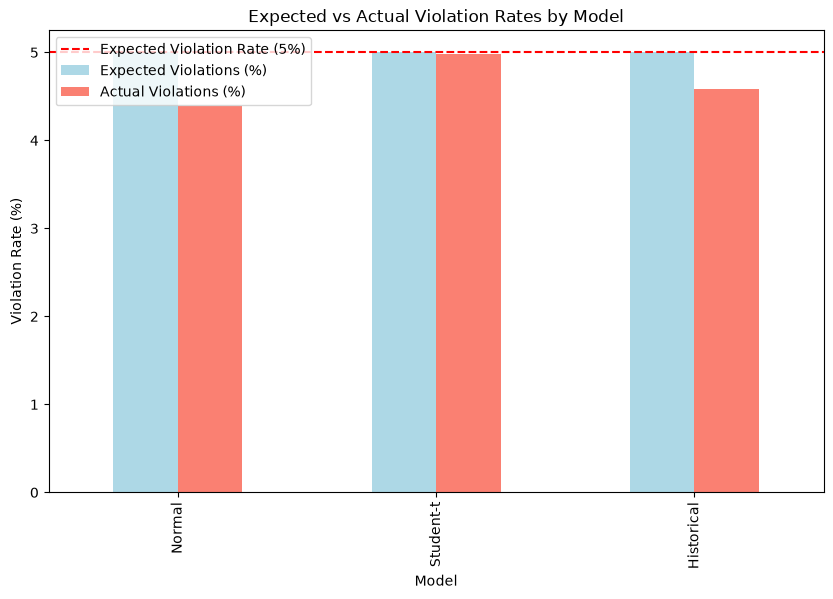

In [ ]:
def plot_violation_rates(backtest_summary): #graphing data from table
    backtest_summary.plot.bar(x='Model', y=['Expected Violations (%)', 'Actual Violations (%)'], figsize=(10, 6), color=['lightblue', 'salmon'])
    plt.axhline(y=5, color='red', linestyle='--', label='Expected Violation Rate (5%)')  # horizontal line at 5%
    plt.title('Expected vs Actual Violation Rates by Model')
    plt.ylabel('Violation Rate (%)')
    plt.legend()    
    plt.show()  # display the plot

plot_violation_rates(backtest_summary)

#### Defining Backtesting Parameters:

- `df_backtest`: Degrees of freedom for the Student-t backtesting model

ANALYZE RESULTS ______________

## 7. Run the Workflow End-to-End

The `main` function encapsulates all programming run in this file. 

In [38]:
def main():
    start_date, end_date = build_window_dates(days_back=365)
    mean_returns, cov_matrix = get_data(stocks, start_date, end_date) #uses 250 recent trading days for normal and Student-t parameter estimates
    mean_m = build_mean_matrix(mean_returns, num_days) #mean_returns column vector repeated num_days times

    historical_stock_returns, portfolio_returns_past_data = get_historical_portfolio_returns(
        stocks,
        weights,
        years_back=5,
    )

    # Define the random number generator before the first use (Normal model)
    # so both the Normal and Student-t models share the same rng.
    rng = np.random.default_rng()

    normal_sims = simulate_normal_model(mean_m, cov_matrix, weights, initial_portfolio, num_days, mc_sims, rng=rng) #simulates full portfolio returns for each day
    t_sims = simulate_student_t_model(mean_m, cov_matrix, weights, initial_portfolio, num_days, mc_sims, df=5, rng=rng)
    hist_sims = simulate_random_day_model(historical_stock_returns, weights, initial_portfolio, num_days, mc_sims, rng=rng)

    results_df = pd.DataFrame({ #creates dataframe with the final portfolio value for each simulation for each model
        'normal': normal_sims[-1, :],
        't': t_sims[-1, :],
        'hist': hist_sims[-1, :],
    })

    risk_summary = summarize_risk(results_df, initial_portfolio, alpha=alpha) #generate VaR and CVaR for each model based on final portfolio returns
    print('Risk Summary')
    print(risk_summary)

    backtest_data, summary = run_var_backtest(
        historical_stock_returns, #returns of each stock each day in 5-year window
        portfolio_returns_past_data, #returns of portfolio as a whole each day in 5-year window
        weights,
        window_backtest=250, #number of days to use for historical data to calculate VaR
        alpha_backtest=5,
        num_sims_backtest=10000,
        df_backtest=5, #same df as used in the Student-t model
    )

    print('\nVaR Backtest Summary')
    print(summary)

In [39]:
# Optional end-to-end rerun:
main()

[*********************100%***********************]  4 of 4 completed
[*********************100%***********************]  4 of 4 completed


Risk Summary
               VaR        CVaR
normal  143.430901  194.408343
t       145.856157  197.014092
hist    240.669177  291.533410

VaR Backtest Summary
        Model  Expected Violations (%)  Actual Violations (%)
0      Normal                      5.0               4.386839
1   Student-t                      5.0               4.985045
2  Historical                      5.0               4.586241


## 8. Conclusions

Since all three model have violation rates below 5% (including the historical portfolio simulation), it can be assumed the VaR estimates are conservative and overestimate risk.


### Limitations:
The degrees of freedom parameter for the Student-t model was fixed at 5 rather than tested through a parameter estimation. As a result, there may be a more optimal specification for the value.

The historical stock returns process preserves relationships between stocks by sampling stock returns from the same days. However, this metholodogy assumes that trading days can be randomly sampled independently. This means the model does not preserve:
- Volatility clustering - periods of high and low volatility are more likely to be followed by periods of the same volatility
- Serial correlation - stock returns for trading days are correlated with its returns from previous days 
- Extended periods of market stress - financial markets experience sustained periods of unusually high volatility, unfavorable economic conditions, or unfavorable economic conditions
- The chronological relationship between market events - the order market movements occur and how one event may be followed by another

### Next Steps:

- Analyzing how results vary for stocks of companies in other industries or sizes (rather than large technology companies)
- The effects of changing weights of stocks in the portfolio (rather than equal amongst each company)
- A larger or smaller simulation horizon for the Monte Carlo simulations to evaluate VaR for portfolio decisions longer or shorter than 1 year. 